# CSD361 Lab Assignment 2

**Student Name:** Suryansh Rohil  
**Roll Number:** 2310110314  
**SNU Email:** sr738@snu.edu.in  
**Notebook:** https://github.com/s-uryansh/CSD361_Intro_To_ML/tree/main/assign2  

## 1. Dataset exploration

I use the Wisconsin diagnostic breast cancer data included with scikit-learn. For this notebook, label 1 means malignant and label 0 means benign.

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, precision_score,
    recall_score, accuracy_score, f1_score, roc_auc_score, roc_curve
)

np.random.seed(42)
plt.rcParams['figure.dpi'] = 100


**1.1.** The dataset has 569 samples and 30 features. The first five features and target names are shown above.

In [47]:
data = load_breast_cancer()
features = data.data
labels = (data.target == 0).astype(int)  # scikit-learn labels malignant as 0

print(f"Dataset shape: {features.shape[0]} samples, {features.shape[1]} features")
print("First five features:", list(data.feature_names[:5]))
print("Original target names:", list(data.target_names))
print("Original counts (malignant, benign):", np.bincount(data.target))
print("Relabeled counts (benign=0, malignant=1):", np.bincount(labels))


Dataset shape: 569 samples, 30 features
First five features: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness')]
Original target names: [np.str_('malignant'), np.str_('benign')]
Original counts (malignant, benign): [212 357]
Relabeled counts (benign=0, malignant=1): [357 212]


**1.2.** There are 212 malignant cases and 357 benign cases. Malignant is encoded as 1; benign as 0.

In [48]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, stratify=labels, random_state=42
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)
print("Train samples:", len(y_train), " Test samples:", len(y_test))
print("Malignant cases in test set:", int(y_test.sum()))


Train samples: 455  Test samples: 114
Malignant cases in test set: 42


**1.3.** The split contains 455 training samples and 114 test samples, including 42 malignant test cases. Keeping test data unseen prevents tuning to it and gives a fairer estimate on new data.

**1.4.** Scaling keeps large-valued features from dominating either model and helps logistic regression optimize. Fit the scaler on training data only; using test data to calculate its statistics is leakage and can inflate test performance.

**1.5.** Positive: malignant. Negative: benign. A false negative misses cancer, while a false positive can cause unnecessary follow-up; a missed cancer is usually the greater cost.

## 2. Logistic regression

Logistic regression is a classifier: it applies the sigmoid to a linear score to estimate the probability of class 1. A threshold, usually 0.5, turns that probability into a label.

**2.1.** It is a classifier because the sigmoid converts a linear score into an estimated probability of class 1. The threshold assigns the final class.

Training accuracy: 0.9868
Test accuracy:     0.9649


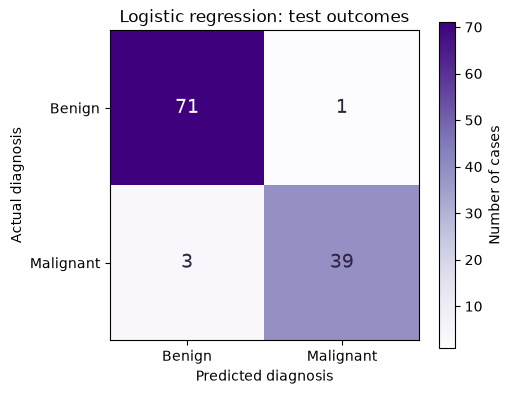

In [49]:
logistic = LogisticRegression(max_iter=1000, random_state=42)
logistic.fit(X_train, y_train)
logistic_pred = logistic.predict(X_test)
logistic_prob = logistic.predict_proba(X_test)[:, 1]

print(f"Training accuracy: {logistic.score(X_train, y_train):.4f}")
print(f"Test accuracy:     {accuracy_score(y_test, logistic_pred):.4f}")
cm_logistic = confusion_matrix(y_test, logistic_pred)
fig, ax = plt.subplots(figsize=(5.2, 4.2))
image = ax.imshow(cm_logistic, cmap='Purples')
for row in range(2):
    for col in range(2):
        ax.text(col, row, str(cm_logistic[row, col]), ha='center', va='center', fontsize=14,
                color='white' if cm_logistic[row, col] > cm_logistic.max() * 0.55 else '#302344')
ax.set_xticks([0, 1], ['Benign', 'Malignant'])
ax.set_yticks([0, 1], ['Benign', 'Malignant'])
ax.set_xlabel('Predicted diagnosis')
ax.set_ylabel('Actual diagnosis')
ax.set_title('Logistic regression: test outcomes')
fig.colorbar(image, ax=ax, label='Number of cases')
fig.tight_layout()
plt.show()


**2.2.** I used `LogisticRegression(max_iter=1000)` on standardized features. The sigmoid gives the malignant probability; the default cutoff is 0.5. Test predictions, confusion matrix, and train/test accuracy are shown above.

In [50]:
tn, fp, fn, tp = cm_logistic.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print(f"Precision: {precision_score(y_test, logistic_pred):.4f}")
print(f"Recall:    {recall_score(y_test, logistic_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, logistic_prob):.4f}")


TN=71, FP=1, FN=3, TP=39
Precision: 0.9750
Recall:    0.9286
ROC-AUC:   0.9960


**2.3.** Precision is TP/(TP+FP) = 39/40 = 0.975; recall is TP/(TP+FN) = 39/42 = 0.929. ROC-AUC is 0.996, showing strong separation between the two classes.

**2.4.** Lowering the threshold usually reduces false negatives and increases false positives; raising it does the reverse. A lower cutoff can suit first-pass cancer screening, where missing a case is costly.

In [51]:
actual_toy = np.array([1, 1, 0, 1, 0, 1, 0, 0, 1, 0])
prob_toy = np.array([.95, .80, .70, .60, .55, .45, .40, .30, .20, .10])
for cutoff in (0.50, 0.30):
    predicted = (prob_toy >= cutoff).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(actual_toy, predicted).ravel()
    print(f"threshold={cutoff:.2f}; predictions={predicted.tolist()}")
    print(f"  TP={tp_t}, FP={fp_t}, TN={tn_t}, FN={fn_t}; "
          f"precision={precision_score(actual_toy, predicted):.2f}, "
          f"recall={recall_score(actual_toy, predicted):.2f}")


threshold=0.50; predictions=[1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
  TP=3, FP=2, TN=3, FN=2; precision=0.60, recall=0.60
threshold=0.30; predictions=[1, 1, 1, 1, 1, 1, 1, 1, 0, 0]
  TP=4, FP=4, TN=1, FN=1; precision=0.50, recall=0.80


At 0.30, recall rises from 0.60 to 0.80 and precision falls from 0.60 to 0.50.

### 2.5. A case where a straight line is not enough

The circles dataset has an inner ring and an outer ring. A straight boundary cannot separate them. Squared coordinates let the model use distance from the origin, which gives a circular boundary in the original plane.

Raw coordinates test accuracy: 0.525
Expanded coordinates test accuracy: 1.000


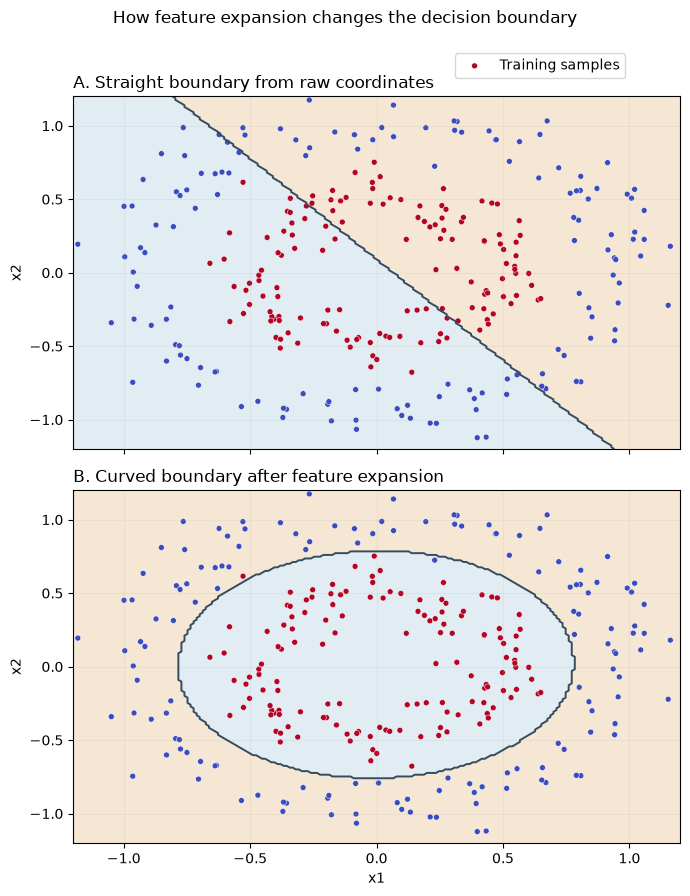

In [52]:
circle_X, circle_y = make_circles(n_samples=400, noise=0.10, factor=0.5, random_state=42)
CX_train, CX_test, cy_train, cy_test = train_test_split(
    circle_X, circle_y, test_size=0.30, stratify=circle_y, random_state=42
)

def expand(X):
    x, y = X[:, 0], X[:, 1]
    return np.column_stack((x, y, x**2, y**2, x*y))

plain_model = LogisticRegression(max_iter=1000).fit(CX_train, cy_train)
expanded_model = LogisticRegression(max_iter=1000).fit(expand(CX_train), cy_train)
print(f"Raw coordinates test accuracy: {plain_model.score(CX_test, cy_test):.3f}")
print(f"Expanded coordinates test accuracy: {expanded_model.score(expand(CX_test), cy_test):.3f}")

xx, yy = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.2, 1.2, 200))
grid = np.column_stack((xx.ravel(), yy.ravel()))
fig, axes = plt.subplots(2, 1, figsize=(7, 9), sharex=True, sharey=True)
for ax, model, transform, title in [
    (axes[0], plain_model, lambda z: z, 'A. Straight boundary from raw coordinates'),
    (axes[1], expanded_model, expand, 'B. Curved boundary after feature expansion')
]:
    region = model.predict(transform(grid)).reshape(xx.shape)
    ax.contourf(xx, yy, region, levels=[-0.5, 0.5, 1.5], colors=['#f4dfc7', '#d8e8ee'], alpha=0.75)
    ax.contour(xx, yy, region, levels=[0.5], colors='#354b5e', linewidths=1.4)
    ax.scatter(CX_train[:, 0], CX_train[:, 1], c=cy_train, cmap='coolwarm', s=18,
               marker='o', edgecolors='white', linewidths=0.35, label='Training samples')
    ax.set_title(title, loc='left')
    ax.set_ylabel('x2')
    ax.grid(alpha=0.15)
axes[1].set_xlabel('x1')
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper right', bbox_to_anchor=(0.91, 0.95))
fig.suptitle('How feature expansion changes the decision boundary', y=0.99)
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


**2.5.** Test accuracy is 0.525 with raw features and 1.000 after expansion. The squared terms capture distance from the origin, so a linear boundary in expanded space becomes circular in the original space.

## 3. Linear support vector machine

A hyperplane is the model's decision boundary. The margin is the gap around that boundary, and the support vectors are the closest training points that set the gap. The SVM chooses a maximum-margin boundary to leave the widest separation it can between the classes.

**3.1.** A hyperplane is the decision boundary; the margin is the gap around it; support vectors are the closest points that determine it. The SVM maximizes the margin to separate classes with the widest gap.

Training accuracy: 0.9890
Test accuracy:     0.9649


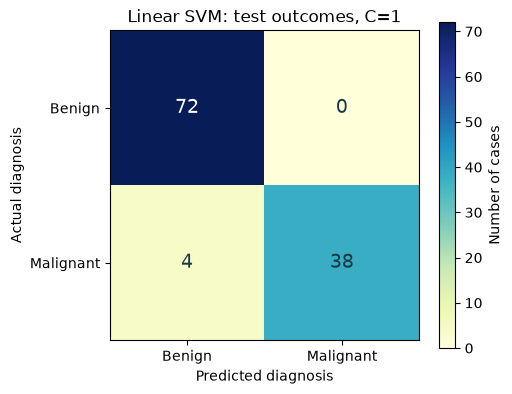

Decision scores are signed distances from the boundary, not probabilities.


In [53]:
svm = SVC(kernel='linear', C=1.0, random_state=42)
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
svm_score = svm.decision_function(X_test)
cm_svm = confusion_matrix(y_test, svm_pred)
print(f"Training accuracy: {svm.score(X_train, y_train):.4f}")
print(f"Test accuracy:     {accuracy_score(y_test, svm_pred):.4f}")
fig, ax = plt.subplots(figsize=(5.2, 4.2))
image = ax.imshow(cm_svm, cmap='YlGnBu')
for row in range(2):
    for col in range(2):
        ax.text(col, row, str(cm_svm[row, col]), ha='center', va='center', fontsize=14,
                color='white' if cm_svm[row, col] > cm_svm.max() * 0.55 else '#183846')
ax.set_xticks([0, 1], ['Benign', 'Malignant'])
ax.set_yticks([0, 1], ['Benign', 'Malignant'])
ax.set_xlabel('Predicted diagnosis')
ax.set_ylabel('Actual diagnosis')
ax.set_title('Linear SVM: test outcomes, C=1')
fig.colorbar(image, ax=ax, label='Number of cases')
fig.tight_layout()
plt.show()
print("Decision scores are signed distances from the boundary, not probabilities.")


**3.2.** I standardized the features because SVM distances depend on scale. With a linear kernel and C=1, train accuracy is 0.989 and test accuracy is 0.965. Its decision scores are signed distances, not probabilities.

In [54]:
tn_s, fp_s, fn_s, tp_s = cm_svm.ravel()
print(f"TN={tn_s}, FP={fp_s}, FN={fn_s}, TP={tp_s}")
print(f"Precision: {precision_score(y_test, svm_pred):.4f}")
print(f"Recall:    {recall_score(y_test, svm_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, svm_score):.4f}")


TN=72, FP=0, FN=4, TP=38
Precision: 1.0000
Recall:    0.9048
ROC-AUC:   0.9914


**3.3.** Precision is 1.000, recall is 0.905, and ROC-AUC is 0.991. The score ranks malignant cases above benign cases well overall.

### Effect of C

A larger C penalizes training errors more strongly. The margin is expected to get narrower, and the model may fit the training data more closely. If test accuracy falls as training accuracy rises, that is a sign of overfitting.

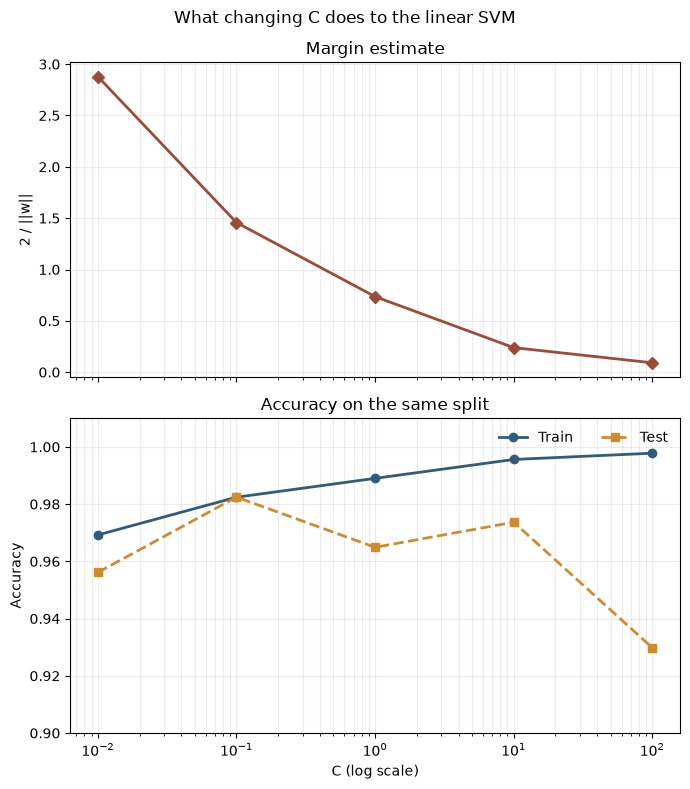

C values: [0.01, 0.1, 1, 10, 100]
Training accuracy: [0.9692, 0.9824, 0.989, 0.9956, 0.9978]
Test accuracy:     [0.9561, 0.9825, 0.9649, 0.9737, 0.9298]


In [55]:
C_values = [0.01, 0.1, 1, 10, 100]
train_scores, test_scores, margin_widths = [], [], []
for value in C_values:
    candidate = SVC(kernel='linear', C=value, random_state=42).fit(X_train, y_train)
    train_scores.append(candidate.score(X_train, y_train))
    test_scores.append(candidate.score(X_test, y_test))
    margin_widths.append(2 / np.linalg.norm(candidate.coef_))

fig, axes = plt.subplots(2, 1, figsize=(7, 8), sharex=True)
axes[0].plot(C_values, margin_widths, color='#9a4c38', marker='D', linewidth=2)
axes[0].set_xscale('log')
axes[0].set_title('Margin estimate')
axes[0].set_ylabel('2 / ||w||')
axes[0].grid(True, which='both', alpha=0.25)
axes[1].plot(C_values, train_scores, color='#315b7d', marker='o', linewidth=2, label='Train')
axes[1].plot(C_values, test_scores, color='#d08b2f', marker='s', linewidth=2, linestyle='--', label='Test')
axes[1].set_xscale('log')
axes[1].set_title('Accuracy on the same split')
axes[1].set_xlabel('C (log scale)')
axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0.90, 1.01)
axes[1].grid(True, which='both', alpha=0.25)
axes[1].legend(frameon=False, ncol=2)
fig.suptitle('What changing C does to the linear SVM')
fig.tight_layout()
plt.show()
print("C values:", C_values)
print("Training accuracy:", [round(v, 4) for v in train_scores])
print("Test accuracy:    ", [round(v, 4) for v in test_scores])


**3.4(A).** Increasing C penalizes margin violations more, so the margin tends to narrow and overfitting becomes more likely. The plots show the margin estimate and train/test accuracy for this dataset.

### Hinge loss and log-loss

Hinge loss is max(0, 1-yf), where y is -1 or 1 and f is the SVM score. It is zero once a point is correctly classified and at least one margin unit away. Log-loss continues to penalize finite scores, with larger penalties for confident mistakes.

Mean hinge loss on test cases: 0.1040
Share with zero hinge loss: 0.904


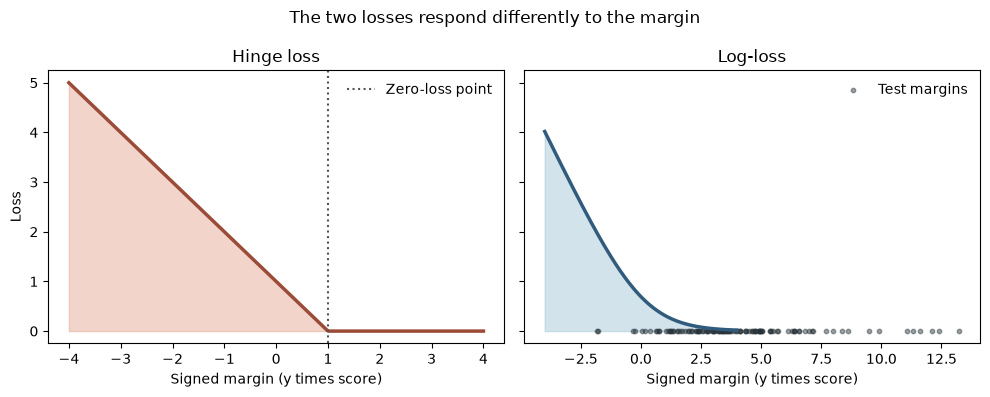

In [56]:
signed_labels = np.where(y_test == 1, 1, -1)
signed_margin = signed_labels * svm_score
hinge_values = np.maximum(0, 1 - signed_margin)
log_values = np.logaddexp(0, -signed_margin)
print(f"Mean hinge loss on test cases: {hinge_values.mean():.4f}")
print(f"Share with zero hinge loss: {(hinge_values == 0).mean():.3f}")

margin_axis = np.linspace(-4, 4, 400)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].fill_between(margin_axis, np.maximum(0, 1 - margin_axis), color='#e6a08c', alpha=0.45)
axes[0].plot(margin_axis, np.maximum(0, 1 - margin_axis), color='#9a4c38', linewidth=2.5)
axes[0].axvline(1, color='#555555', linestyle=':', label='Zero-loss point')
axes[0].set_title('Hinge loss')
axes[0].set_xlabel('Signed margin (y times score)')
axes[0].set_ylabel('Loss')
axes[0].legend(frameon=False)
axes[1].fill_between(margin_axis, np.logaddexp(0, -margin_axis), color='#a7c8d8', alpha=0.5)
axes[1].plot(margin_axis, np.logaddexp(0, -margin_axis), color='#315b7d', linewidth=2.5)
axes[1].set_title('Log-loss')
axes[1].set_xlabel('Signed margin (y times score)')
axes[1].scatter(signed_margin, np.zeros_like(signed_margin), s=10, color='#263238', alpha=0.45, label='Test margins')
axes[1].legend(frameon=False)
fig.suptitle('The two losses respond differently to the margin')
fig.tight_layout()
plt.show()


**3.4(B).** Hinge loss is zero when y*f is at least 1 and penalizes points inside that margin. Log-loss remains positive for finite scores and penalizes confident errors more.

## 4. Comparing the models

At the default threshold, precision asks how many predicted cancers were malignant; recall asks how many actual cancers were found. Accuracy is the share of correct predictions, and F1 is the harmonic mean of precision and recall.

In [57]:
def summarize(name, prediction, score):
    tn, fp, fn, tp = confusion_matrix(y_test, prediction).ravel()
    return {
        'Model': name, 'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
        'Precision': precision_score(y_test, prediction),
        'Recall': recall_score(y_test, prediction),
        'Accuracy': accuracy_score(y_test, prediction),
        'F1': f1_score(y_test, prediction),
        'ROC-AUC': roc_auc_score(y_test, score),
    }

comparison = pd.DataFrame([
    summarize('Logistic regression', logistic_pred, logistic_prob),
    summarize('Linear SVM', svm_pred, svm_score),
]).set_index('Model')
print(comparison.round(4).to_string())


                     TP  FP  TN  FN  Precision  Recall  Accuracy      F1  ROC-AUC
Model                                                                            
Logistic regression  39   1  71   3      0.975  0.9286    0.9649  0.9512   0.9960
Linear SVM           38   0  72   4      1.000  0.9048    0.9649  0.9500   0.9914


**4.1.** Precision=TP/(TP+FP); recall=TP/(TP+FN); accuracy=(TP+TN)/N; F1=2PR/(P+R). Here, false positives are benign cases sent for follow-up, and false negatives are missed cancers.

**4.2.** The table reports TP, FP, TN, FN, precision, recall, accuracy, F1, and ROC-AUC for both models on the same test set.

           TP  FP  TN  FN  Precision  Recall     FPR     TPR
Threshold                                                   
0.3        41   1  71   1     0.9762  0.9762  0.0139  0.9762
0.5        39   1  71   3     0.9750  0.9286  0.0139  0.9286
0.7        38   0  72   4     1.0000  0.9048  0.0000  0.9048


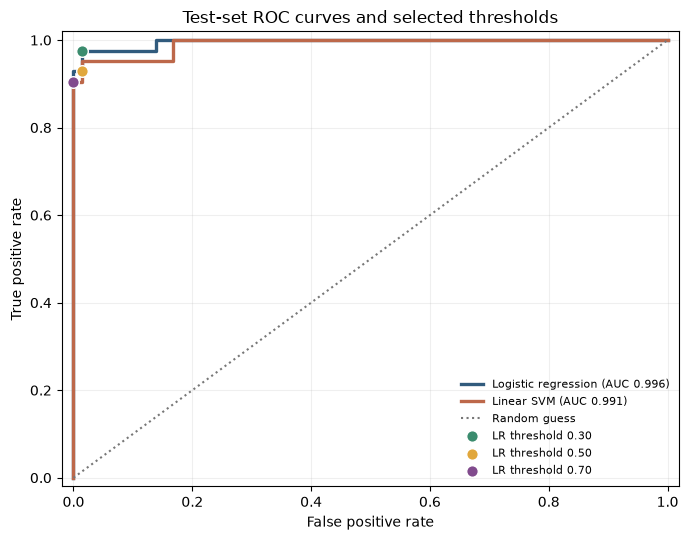

In [58]:
threshold_rows = []
for cutoff in (0.30, 0.50, 0.70):
    prediction = (logistic_prob >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, prediction).ravel()
    threshold_rows.append({
        'Threshold': cutoff, 'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
        'Precision': precision_score(y_test, prediction),
        'Recall': recall_score(y_test, prediction),
        'FPR': fp / (fp + tn), 'TPR': tp / (tp + fn),
    })
print(pd.DataFrame(threshold_rows).set_index('Threshold').round(4).to_string())

fpr_lr, tpr_lr, _ = roc_curve(y_test, logistic_prob)
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_score)
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.step(fpr_lr, tpr_lr, where='post', color='#315b7d', linewidth=2.4,
        label=f'Logistic regression (AUC {roc_auc_score(y_test, logistic_prob):.3f})')
ax.step(fpr_svm, tpr_svm, where='post', color='#bd684a', linewidth=2.4,
        label=f'Linear SVM (AUC {roc_auc_score(y_test, svm_score):.3f})')
ax.plot([0, 1], [0, 1], color='#777777', linestyle=':', label='Random guess')
for cutoff, marker_color in zip((0.30, 0.50, 0.70), ('#3b8c6e', '#e1a73c', '#814b8d')):
    prediction = (logistic_prob >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, prediction).ravel()
    point_fpr, point_tpr = fp / (fp + tn), tp / (tp + fn)
    ax.scatter(point_fpr, point_tpr, s=70, color=marker_color, edgecolor='white', zorder=4,
               label=f'LR threshold {cutoff:.2f}')
ax.set_title('Test-set ROC curves and selected thresholds')
ax.set_xlabel('False positive rate')
ax.set_ylabel('True positive rate')
ax.set_xlim(-0.02, 1.02)
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.2)
ax.legend(frameon=False, fontsize=8, loc='lower right')
fig.tight_layout()
plt.show()


**4.3.** The threshold table gives confusion counts, precision, recall, and each operating point. Lowering the threshold moves toward higher TPR and usually higher FPR; ROC-AUC summarizes ranking across thresholds.

**4.4.** The confusion matrix, precision, and recall describe performance at one threshold; ROC and AUC compare thresholds. I would use logistic regression for first-pass screening because it missed fewer cancers here. The SVM’s higher precision may help when follow-up is costly.

**4.5(a).** No. Logistic regression has both higher AUC and recall here; they can differ because AUC covers all thresholds while recall uses 0.5.

**4.5(b).** Both models have 96.5% accuracy, but that hides their different error counts. I would also compare recall, precision, and AUC.

**4.5(c).** A large train/test accuracy gap suggests overfitting. Larger C penalizes violations more and can increase that gap.